# Progetto — Fondamenti di Analisi dei Dati

**Gruppo:** Filippo Emiliano Occhino  
**Dataset assegnato:** Online Shoppers Purchasing Intention


# 1.Comprensione del dataset

### 1.1 Caricamento e prima ispezione

In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import pandas as pd
df=pd.read_csv("../data/online_shoppers_intention.csv")
df.index.name = "Session_ID"
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

In [2]:
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
Session_ID,,,,,,,,,,,,,,,,,,
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [3]:
df.columns

Index(['Administrative', 'Administrative_Duration', 'Informational',
       'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
       'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month',
       'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType',
       'Weekend', 'Revenue'],
      dtype='object')

### 1.2 Dizionario dei dati

| Nome Variabile | Descrizione | Unità di misura | Tipo di Dato |
| :--- | :--- | :--- | :--- |
| **Administrative** | Numero di pagine di tipo amministrativo visitate | Pagine (Conteggio) | Numerica (discreta) |
| **Administrative_Duration** | Tempo totale trascorso sulle pagine amministrative | Secondi | Numerica (continua) |
| **Informational** | Numero di pagine informative visitate | Pagine (Conteggio) | Numerica (discreta) |
| **Informational_Duration** | Tempo totale trascorso sulle pagine informative | Secondi | Numerica (continua) |
| **ProductRelated** | Numero di pagine relative ai prodotti visitate | Pagine (Conteggio) | Numerica (discreta) |
| **ProductRelated_Duration** | Tempo totale trascorso visualizzando pagine di prodotti | Secondi | Numerica (continua) |
| **BounceRates** | Percentuale di visitatori che entrano ed escono senza interazioni | Percentuale | Numerica (continua) |
| **ExitRates** | Percentuale di uscite dal sito calcolata per la specifica pagina | Percentuale | Numerica (continua) |
| **PageValues** | Valore medio della pagina visitata rispetto alle transazioni | Valuta | Numerica (continua) |
| **SpecialDay** | Vicinanza della data di visita a un giorno speciale/festivo | Nessuna (Indice) | Numerica (continua) |
| **Month** | Mese dell'anno in cui è avvenuta la sessione | Mesi | Categorica (ordinale) |
| **OperatingSystems** | Sistema operativo utilizzato (codificato in numero) | Nessuna | Categorica (nominale) |
| **Browser** | Browser utilizzato (codificato in numero) | Nessuna | Categorica (nominale) |
| **Region** | Regione geografica dell'utente (codificata in numero) | Nessuna | Categorica (nominale) |
| **TrafficType** | Sorgente di traffico da cui proviene l'utente | Nessuna | Categorica (nominale) |
| **VisitorType** | Tipologia di visitatore (es. nuovo o di ritorno) | Nessuna | Categorica (nominale) |
| **Weekend** | Indica se la sessione è avvenuta nel fine settimana | Nessuna | Categorica (nominale) |
| **Revenue** | Indica se la visita si è conclusa con un acquisto | Nessuna | Categorica (nominale) |

### 1.3 Domande dell'analisi

1) Il numero di pagine di prodotto visitate e il tempo trascorso su di esse aumentano concretamente la probabilità di acquisto?
2) Esistono mesi dell'anno più redditizi? La vicinanza a un giorno speciale si traduce in acquisti reali, oppure spinge solo gli utenti a navigare senza concludere?
3) Quale Area geografica porta gli utenti che acquistano di più?
4) I nuovi visitatori tendono ad abbandonare il sito più facilmente rispetto a quelli di ritorno? I clienti storici navigano su pagine di maggior valore statistico?
5) Esiste una forte correlazione tra il valore storico delle pagine esplorate e l'effettivo completamento dell'acquisto?

## 2. Pulizia e preparazione

### 2.1 Valori mancanti


In [4]:
print(df.isnull().sum())

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64


Come primo passo per la pulizia, verifichiamo la presenza di eventuali valori mancanti nel dataset. Come si evince dall'output, tutte le colonne hanno un conteggio uguale a zero: non essendo presente alcun valore nullo, possiamo saltare le operazioni di imputazione o rimozione delle righe.

### 2.2 Righe duplicate

In [5]:
righe_iniziali=len(df)
print("Righe iniziali:",righe_iniziali)

print("Righe duplicate:",df.duplicated().sum())
df = df.drop_duplicates().copy()

righe_finali = len(df)
print("Righe rimaste dopo l'eliminazione dei duplicati:",righe_finali)


Righe iniziali: 12330
Righe duplicate: 125
Righe rimaste dopo l'eliminazione dei duplicati: 12205


Sono state identificate 125 righe duplicate (pari a circa l'1% del dataset), riconducibili principalmente a sessioni a rimbalzo immediato. Si procede alla loro rimozione.

### 2.3 Tipi e incoerenze

In [6]:
#Uniformazione dei mesi
df['Month'].unique()
df['Month']=df['Month'].replace({'June':'Jun'})

#Definizione del tipo ordinale per i mesi
mesi_ordinati = ['Feb', 'Mar', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
df['Month'] = pd.Categorical(df['Month'], categories=mesi_ordinati, ordered=True)

#Conversione da int a category delle variabili nominali
df['OperatingSystems']=df['OperatingSystems'].astype('category')
df['Browser']=df['Browser'].astype('category')
df['Region']=df['Region'].astype('category')
df['TrafficType']=df['TrafficType'].astype('category')
df['VisitorType']=df['VisitorType'].astype('category')

In questa fase correggiamo le incoerenze formali e allineiamo i tipi di dato al loro reale significato:

-Uniformazione di Month: June viene rinominato in Jun per coerenza con le altre abbreviazioni a 3 lettere del dataset.  
-Definizione del tipo ordinale per i mesi: Month viene convertito da semplice testo a categorica ordinale (pd.Categorical), così da garantire il corretto ordine cronologico nei grafici ed evitare che vengano disposti in ordine alfabetico.  
-Conversione delle categoriche nominali (int64 → category): OperatingSystems, Browser, Region, TrafficType e VisitorType sono codici identificativi privi di valore quantitativo (non ha senso calcolarne media o deviazione standard). Vengono quindi convertiti in category per evitare che vengano trattati come numeri continui.

### 2.4 Valori anomali

In [7]:
df.describe()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay
count,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000
mean,2.338878,81.646331,0.508726,34.825454,32.045637,1206.982457,0.020370,0.041466,5.949574,0.061942
std,3.330436,177.491845,1.275617,141.424807,44.593649,1919.601400,0.045255,0.046163,18.653671,0.199666
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,8.000000,193.000000,0.000000,0.014231,0.000000,0.000000
50%,1.000000,9.000000,0.000000,0.000000,18.000000,608.942857,0.002899,0.025000,0.000000,0.000000
75%,4.000000,94.700000,0.000000,0.000000,38.000000,1477.154762,0.016667,0.048529,0.000000,0.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000


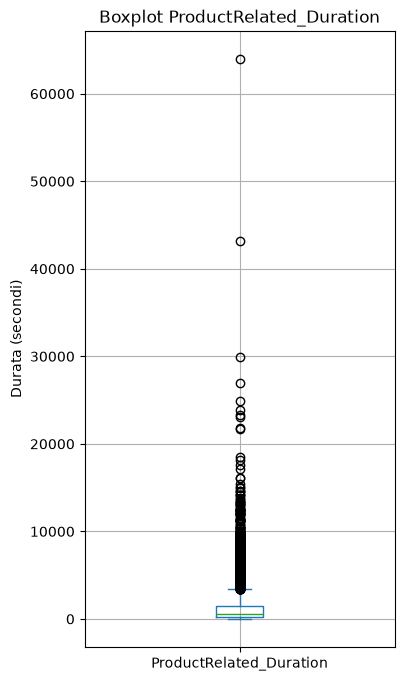

In [16]:
import matplotlib.pyplot as plt

df['ProductRelated_Duration'].plot.box(figsize=(4,8))
plt.title('Boxplot ProductRelated_Duration')
plt.ylabel('Durata (secondi)')
plt.grid()
plt.show()

Il boxplot di ProductRelated_Duration evidenzia una forte asimmetria positiva: il 75% degli utenti trascorre meno di 25 minuti sui prodotti (con una mediana di circa 10 minuti), mentre si osserva una fitta scia di outlier che raggiunge un massimo di quasi 18 ore. Trattandosi di comportamenti reali (es. schede lasciate aperte nel browser), non sono errori di inserimento e vengono mantenuti.

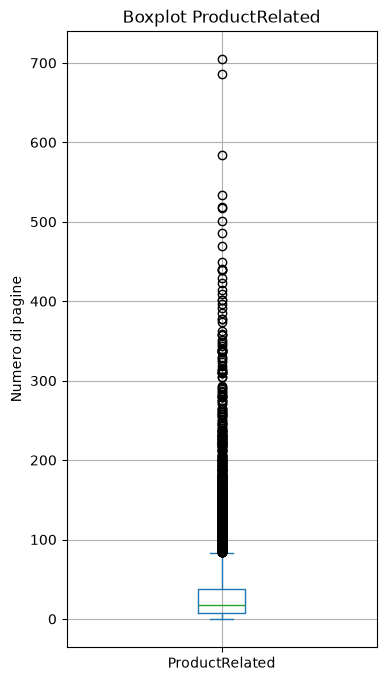

In [17]:
df['ProductRelated'].plot.box(figsize=(4,8))
plt.title('Boxplot ProductRelated')
plt.ylabel('Numero di pagine')
plt.grid()
plt.show()

Anche per ProductRelated la distribuzione presenta una marcata asimmetria a destra: la mediana è di 18 pagine e il 75% degli utenti ne visita fino a 38, ma sono presenti outlier estremi che arrivano fino a 705 pagine consultate in una singola sessione.

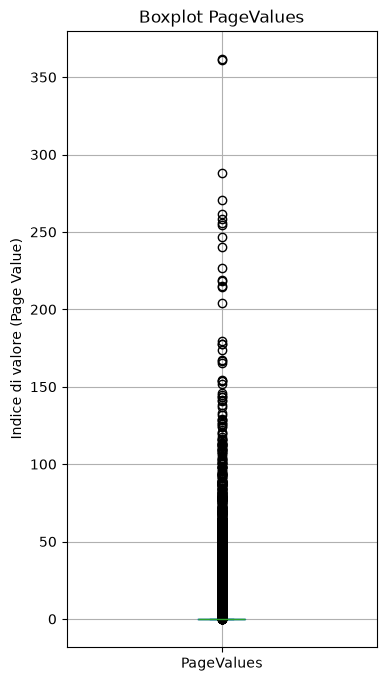

In [18]:
df['PageValues'].plot.box(figsize=(4,8))
plt.title('Boxplot PageValues')
plt.ylabel('Indice di valore (Page Value)')
plt.grid()
plt.show()

Oltre il 75% delle sessioni presenta PageValues pari a 0, poiché la maggior parte degli utenti non conclude acquisti o non visita pagine con valore economico storico. Gli outlier rappresentano le sessioni ad alto valore di conversione, con valori che superano quota 300.

Sintesi e decisioni sui valori anomali: Tutti gli outlier identificati corrispondono a dinamiche legittime del traffico web (lunghe permanenze, consultazioni intensive o transazioni importanti) e non a errori tecnici di inserimento dati. Vengono pertanto interamente mantenuti per non alterare la rappresentatività del campione reale.

# 3. Analisi esplorativa

## Variabili discrete

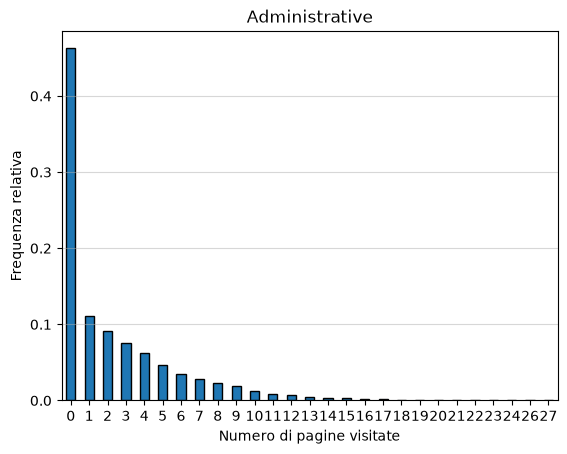

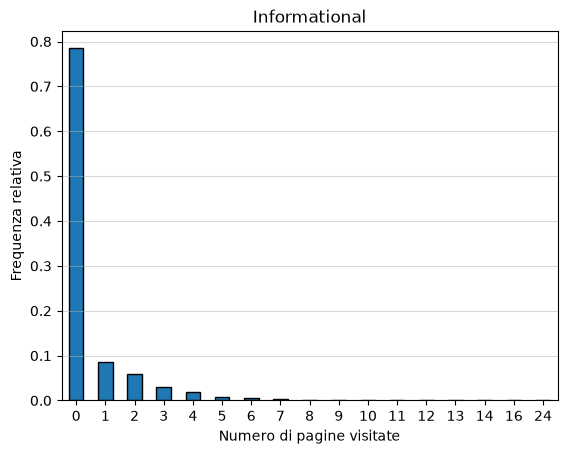

In [19]:
from matplotlib import pyplot as plt

for colname in ['Administrative', 'Informational']:
    df[colname].value_counts(normalize=True).sort_index().plot(kind='bar', title=colname, rot=0, edgecolor='black')
    plt.xlabel('Numero di pagine visitate')
    plt.ylabel('Frequenza relativa')
    plt.grid(axis='y', alpha=0.5)
    plt.show()

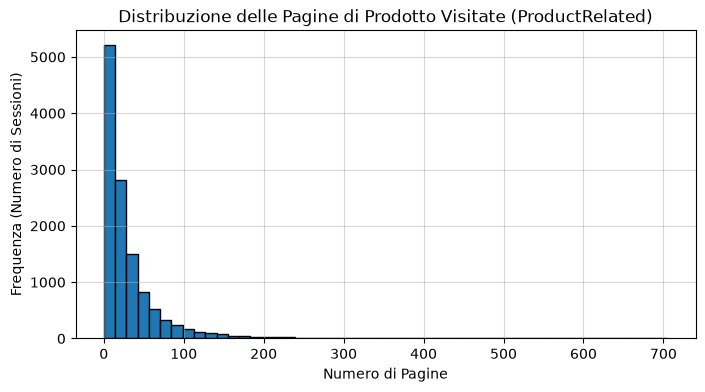

In [15]:
import matplotlib.pyplot as plt

df['ProductRelated'].plot(kind='hist', bins=50, figsize=(8, 4), edgecolor='black')
plt.title('Distribuzione delle Pagine di Prodotto Visitate (ProductRelated)')
plt.xlabel('Numero di Pagine')
plt.ylabel('Frequenza (Numero di Sessioni)')
plt.grid(True, alpha=0.5)

plt.show()

In [20]:
colonne = ['Administrative', 'Informational', 'ProductRelated']
display(df[colonne].describe())
display(df[colonne].mode())

,Administrative,Informational,ProductRelated
count,12205.000000,12205.000000,12205.000000
mean,2.338878,0.508726,32.045637
std,3.330436,1.275617,44.593649
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,8.000000
50%,1.000000,0.000000,18.000000
75%,4.000000,0.000000,38.000000
max,27.000000,24.000000,705.000000


,Administrative,Informational,ProductRelated
0,0,0,1


Dall'analisi delle variabili discrete di navigazione emerge che:  
-Informational: è la tipologia di pagina meno consultata in assoluto; oltre l'80% delle sessioni non registra alcuna visita a pagine informative (moda e mediana pari a 0).  
-Administrative: oltre il 45% delle sessioni non consulta pagine amministrative/gestionali (moda pari a 0, mediana pari a 1).  
-ProductRelated: rappresenta il vero nucleo della navigazione; tutti gli utenti visitano pagine prodotto, con una mediana di 18 pagine e una media di circa 32 (evidente asimmetria positiva dovuta a sessioni con un numero molto elevato di visualizzazioni).  

## Variabili continue

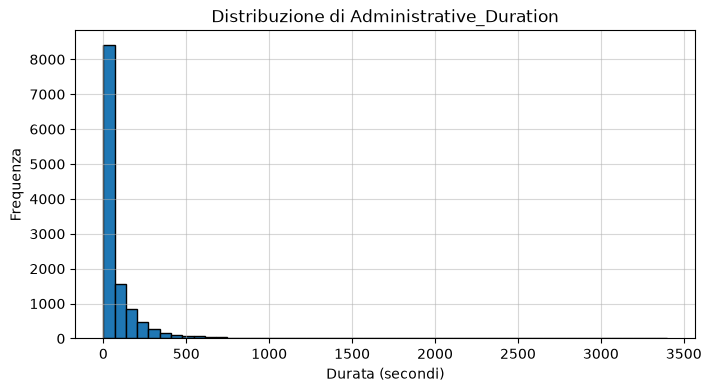

In [21]:
df['Administrative_Duration'].plot(kind='hist', bins=50, figsize=(8, 4), edgecolor='black')
plt.title('Distribuzione di Administrative_Duration')
plt.xlabel('Durata (secondi)')
plt.ylabel('Frequenza')
plt.grid(True, alpha=0.5)
plt.show()

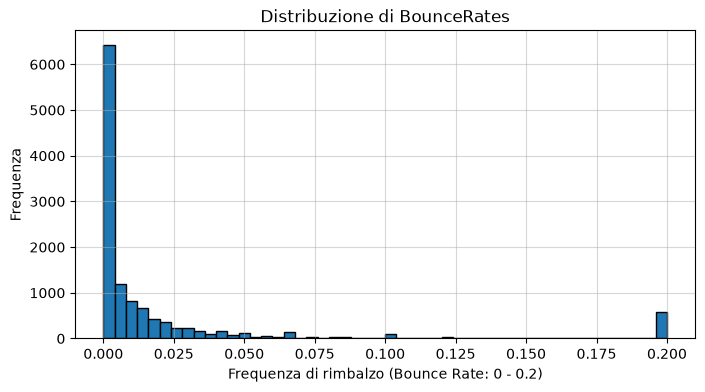

In [22]:
df['BounceRates'].plot(kind='hist', bins=50, figsize=(8, 4), edgecolor='black')
plt.title('Distribuzione di BounceRates')
plt.xlabel('Frequenza di rimbalzo (Bounce Rate: 0 - 0.2)')
plt.ylabel('Frequenza')
plt.grid(True, alpha=0.5)
plt.show()

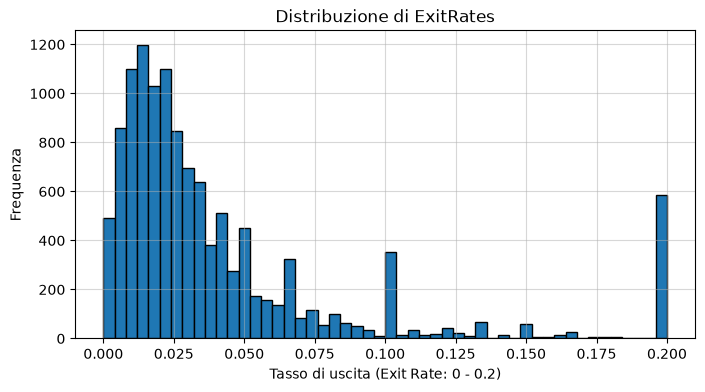

In [23]:
df['ExitRates'].plot(kind='hist', bins=50, figsize=(8, 4), edgecolor='black')
plt.title('Distribuzione di ExitRates')
plt.xlabel('Tasso di uscita (Exit Rate: 0 - 0.2)')
plt.ylabel('Frequenza')
plt.grid(True, alpha=0.5)
plt.show()

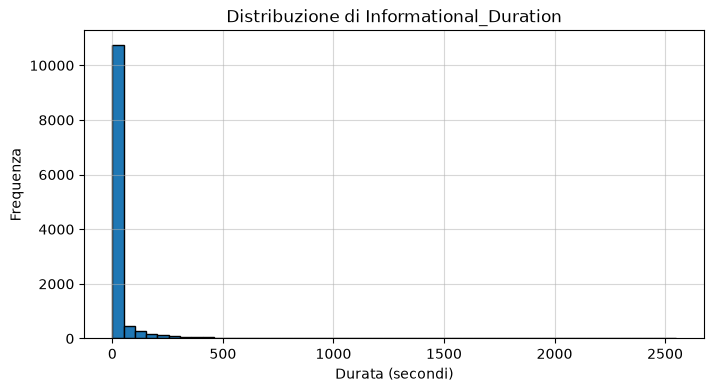

In [24]:
df['Informational_Duration'].plot(kind='hist', bins=50, figsize=(8, 4), edgecolor='black')
plt.title('Distribuzione di Informational_Duration')
plt.xlabel('Durata (secondi)')
plt.ylabel('Frequenza')
plt.grid(True, alpha=0.5)
plt.show()

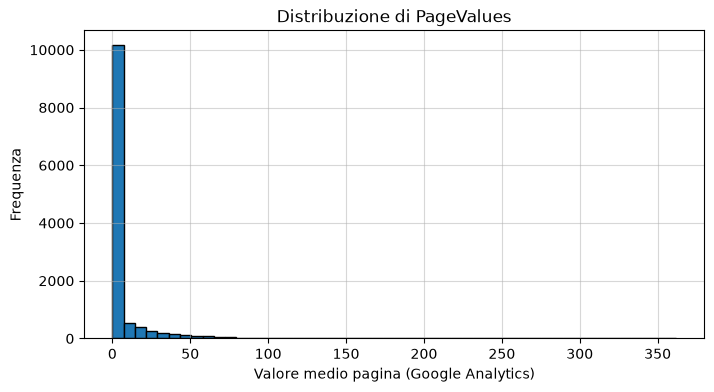

In [25]:
df['PageValues'].plot(kind='hist', bins=50, figsize=(8, 4), edgecolor='black')
plt.title('Distribuzione di PageValues')
plt.xlabel('Valore medio pagina (Google Analytics)')
plt.ylabel('Frequenza')
plt.grid(True, alpha=0.5)
plt.show()

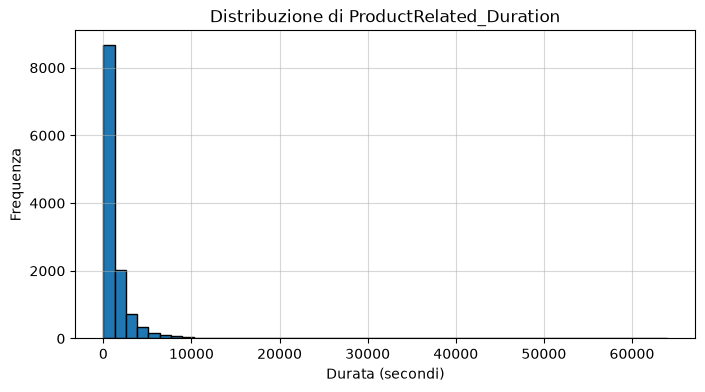

In [26]:
df['ProductRelated_Duration'].plot(kind='hist', bins=50, figsize=(8, 4), edgecolor='black')
plt.title('Distribuzione di ProductRelated_Duration')
plt.xlabel('Durata (secondi)')
plt.ylabel('Frequenza')
plt.grid(True, alpha=0.5)
plt.show()

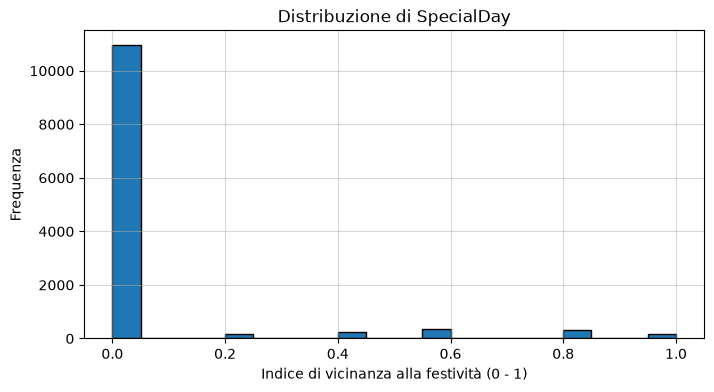

In [27]:
df['SpecialDay'].plot(kind='hist', bins=20, figsize=(8, 4), edgecolor='black')
plt.title('Distribuzione di SpecialDay')
plt.xlabel('Indice di vicinanza alla festività (0 - 1)')
plt.ylabel('Frequenza')
plt.grid(True, alpha=0.5)
plt.show()

In [28]:
continue_cols=['Administrative_Duration','BounceRates','ExitRates','Informational_Duration','PageValues','ProductRelated_Duration','SpecialDay']
df[continue_cols].describe()

,Administrative_Duration,BounceRates,ExitRates,Informational_Duration,PageValues,ProductRelated_Duration,SpecialDay
count,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000
mean,81.646331,0.020370,0.041466,34.825454,5.949574,1206.982457,0.061942
std,177.491845,0.045255,0.046163,141.424807,18.653671,1919.601400,0.199666
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.014231,0.000000,0.000000,193.000000,0.000000
50%,9.000000,0.002899,0.025000,0.000000,0.000000,608.942857,0.000000
75%,94.700000,0.016667,0.048529,0.000000,0.000000,1477.154762,0.000000
max,3398.750000,0.200000,0.200000,2549.375000,361.763742,63973.522230,1.000000


Dall'analisi delle variabili discrete di navigazione emerge che:  
-Asimmetria marcata: tutte le durate e PageValues hanno una fortissima asimmetria a destra con la maggior parte delle sessioni schiacciata sullo zero.  
Tassi di rimbalzo e uscita (BounceRates, ExitRates): sono concentrati su valori bassi (< 0.05), ma presentano un picco secondario a 0.2 (il valore massimo assegnato di default da Google Analytics quando l'utente abbandona il sito subito dopo la prima pagina).  
Festività (SpecialDay): la stragrande maggioranza delle visite (oltre l'85%) avviene in giorni ordinari (valore 0).  

## Variabili categoriche

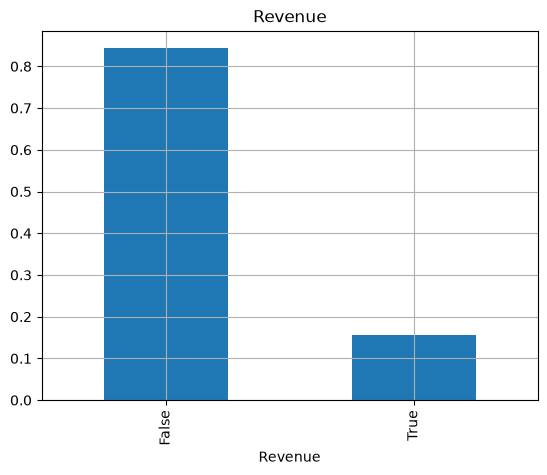

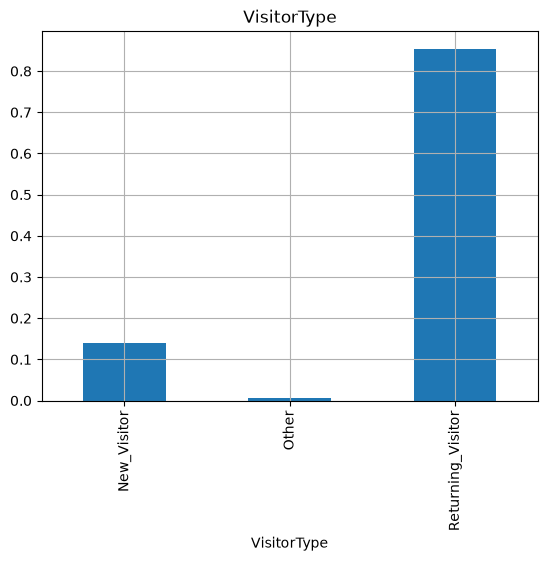

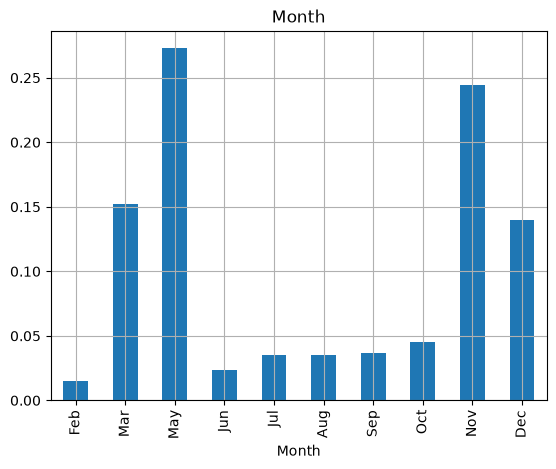

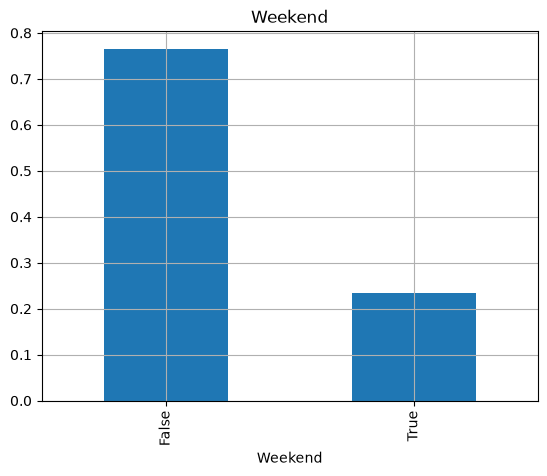

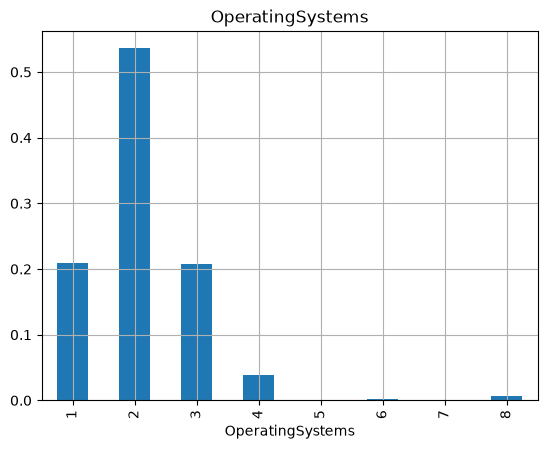

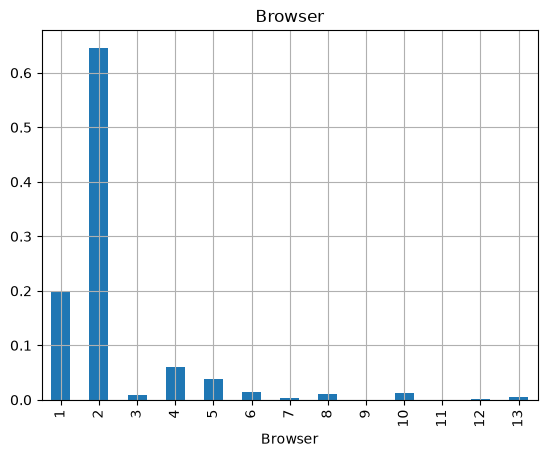

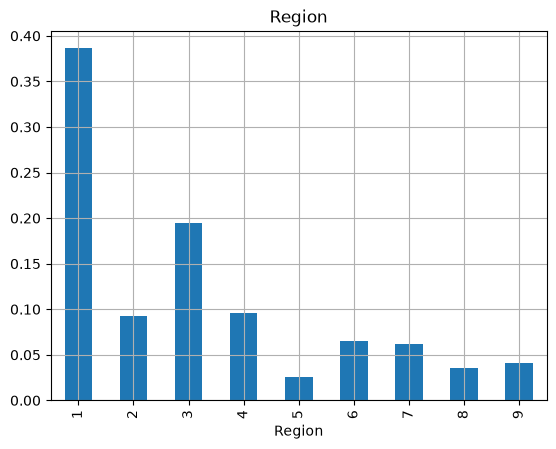

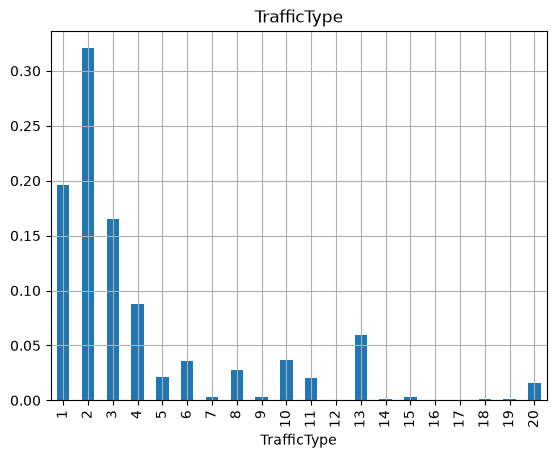

In [31]:
colonne_categoriche = ['Revenue', 'VisitorType', 'Month', 'Weekend', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']

for colname in colonne_categoriche:
    df[colname].value_counts(normalize=True).sort_index().plot(kind='bar', title=colname)
    plt.grid()
    plt.show()

In [32]:
df[colonne_categoriche].describe()

,Revenue,VisitorType,Month,Weekend,OperatingSystems,Browser,Region,TrafficType
count,12205,12205,12205,12205,12205,12205,12205,12205
unique,2,3,10,2,8,13,9,20
top,False,Returning_Visitor,May,False,2,2,1,2
freq,10297,10431,3329,9346,6541,7883,4714,3911


Dall'analisi delle variabili categoriche emerge che:  
-Revenue (Target): forte sbilanciamento di classe; solo il ~15.5% delle sessioni si conclude con un acquisto, a fronte di un ~84.5% senza conversione.  
-VisitorType: netta prevalenza dei visitatori abituali (*Returning_Visitor*, circa l'85%), mentre i nuovi utenti rappresentano circa il 14%.  
-Month: forte stagionalità con picchi a Maggio e Novembre (periodo Black Friday/inizio shopping natalizio). Si nota l'assenza totale di Gennaio e Aprile nel dataset.  
-Weekend: circa il 76% delle sessioni avviene nei giorni feriali e il 24% nel fine settimana.  
-Variabili contestuali (OperatingSystems, Browser, Region, TrafficType): forte concentrazione; la grande maggioranza degli utenti impiega solo 2-3 sistemi operativi e browser dominanti, con sorgenti di traffico e regioni geografiche altamente polarizzate.  

## Ripartizione del lavoro e uso dell'AI generativa

*(chi ha fatto che cosa, e come avete usato strumenti di AI generativa: per che cosa, con quali verifiche, e che cosa avete scritto voi.)*
